# Aurora Finance: the analysis, step by step

This notebook walks through the analysis behind the app, using **synthetic data**: two years
of an invented household generated by `ledger/demo.py` and categorized by the app's real
rules. Every function used here is the same one the app uses (`insights/`, plain pandas).

**Questions**
1. Where does the money go, and is the household saving?
2. Which payments are recurring, and which went up in price?
3. Which months were unusual, and how do we decide that without being fooled by spikes?
4. What is a realistic budget?
5. How much does paying extra on the loans save?

In [1]:
import io
import os
import sys
from datetime import date
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.environ.setdefault("DJANGO_SETTINGS_MODULE", "config.settings")
os.environ["DB_PATH"] = ":memory:"  # synthetic data only; nothing is written to disk
os.environ["DJANGO_ALLOW_ASYNC_UNSAFE"] = "true"  # Jupyter runs an event loop

import django

django.setup()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from django.core.management import call_command

from insights import anomalies, budget, debt, monthly, patterns, recurring, trends
from ledger.frames import transactions_df

END = date(2026, 10, 31)  # fixed, so the notebook is reproducible
TODAY = pd.Timestamp("2026-11-01")
call_command("migrate", verbosity=0)
call_command("make_demo_data", end=END, stdout=io.StringIO())

plt.rcParams.update(
    {
        "figure.figsize": (10, 3.6),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
    }
)
BLUE, ORANGE, GREY = "#2f6fdb", "#e0682b", "#8a8f98"

df = transactions_df()
print(f"{len(df)} transactions, {df['date'].min():%d.%m.%Y} to {df['date'].max():%d.%m.%Y}")
df.head()

963 transactions, 01.11.2024 to 31.10.2026


,id,date,account,amount,description,merchant,category,group,category_id,group_id,kind
0,1,2024-11-01,Brukskonto,-549.00,Sats Norge AS,sats norge,Training,Bills,19.0,15.0,fixed
1,2,2024-11-01,Brukskonto,-88.28,Vipps:Easypark Norge,easypark norge,Parking & tolls,Transport,30.0,28.0,variable
2,3,2024-11-01,Brukskonto,-113.90,Kiwi Torshov,kiwi torshov,Groceries,Food,26.0,25.0,variable
3,742,2024-11-01,Regningskonto,-13900.00,Husleie Storgata 12 Utleie AS,husleie storgata,Rent & mortgage,Housing,13.0,12.0,fixed
4,4,2024-11-02,Brukskonto,-899.00,Vipps:Ruter Månedsbillett,ruter månedsbillett,Public transport & taxi,Transport,31.0,28.0,variable


## 1. Data quality first

Before any analysis: how much of the data did the rules categorize, and does every month
have a similar number of rows? A thin month would look like a drop in spending.

In [2]:
share = df["category"].notna().mean()
print(f"Categorized by rules: {share:.1%}")
print("Uncategorized merchants:", sorted(df.loc[df["category"].isna(), "merchant"].unique()))
df.groupby([df["date"].dt.to_period("M"), "account"]).size().unstack().tail(6)

Categorized by rules: 99.2%
Uncategorized merchants: ['loppemarked sagene', 'skatteetaten skatt']


account,Brukskonto,Regningskonto
date,,
2026-05,23,9
2026-06,27,10
2026-07,40,9
2026-08,34,9
2026-09,28,9
2026-10,29,9


## 2. Money in, money out

Every row gets a **flow**: income, spending, transfer (between own accounts, savings) or
netted. Transfers are not spending, or moving money to the card account would count twice.
Refunds lower spending instead of counting as income.

`complete_months` drops the current month: a half month would read as a drop.

In [3]:
summary = monthly.complete_months(monthly.monthly_summary(df), TODAY)
summary[["income", "spending", "net", "savings_rate"]].tail(6)

flow,income,spending,net,savings_rate
2026-05,39847.5,31187.52,8659.98,21.73
2026-06,44717.5,32286.05,12431.45,27.80
2026-07,39847.5,47778.46,-7930.96,-19.90
2026-08,39847.5,48149.05,-8301.55,-20.83
2026-09,39847.5,33462.08,6385.42,16.02
2026-10,39847.5,31911.44,7936.06,19.92


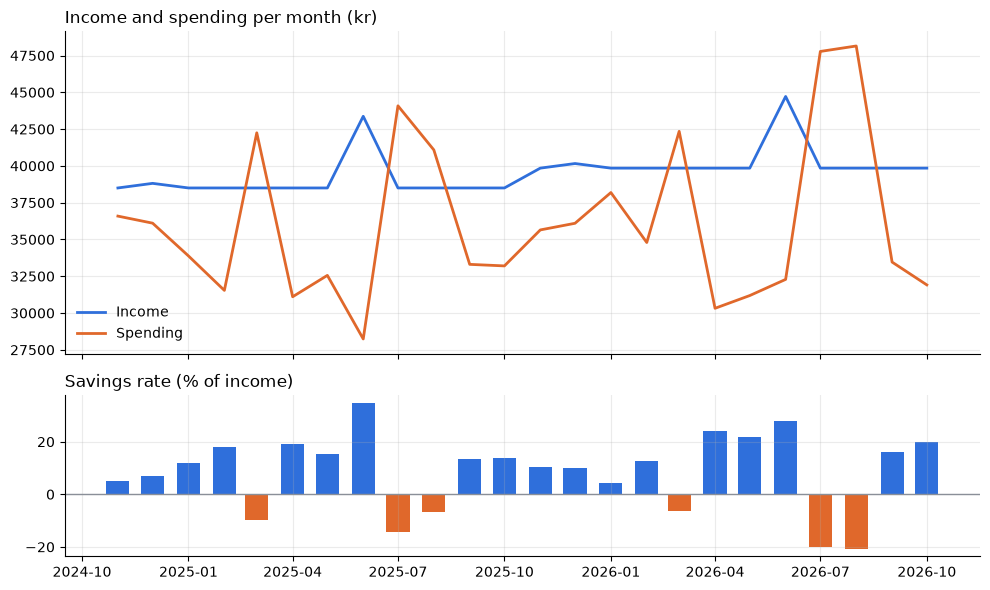

In [4]:
x = summary.index.to_timestamp()
fig, (top, bottom) = plt.subplots(
    2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]}
)
top.plot(x, summary["income"], color=BLUE, lw=2, label="Income")
top.plot(x, summary["spending"], color=ORANGE, lw=2, label="Spending")
top.set_title("Income and spending per month (kr)", loc="left")
top.legend(frameon=False, loc="lower left")
bottom.bar(
    x, summary["savings_rate"], width=20, color=np.where(summary["savings_rate"] >= 0, BLUE, ORANGE)
)
bottom.axhline(0, color=GREY, lw=1)
bottom.set_title("Savings rate (% of income)", loc="left")
plt.tight_layout()

In [5]:
rate = summary["net"].tail(12).sum() / summary["income"].tail(12).sum() * 100
worst = summary["net"].idxmin()
print(f"Savings rate, last 12 months: {rate:.1f} %")
print(f"Weakest month: {worst} ({summary.loc[worst, 'net']:,.0f} kr)")

Savings rate, last 12 months: 8.5 %
Weakest month: 2026-08 (-8,302 kr)


Two years of steady income with a raise in the second year, and a savings rate just
under 10 %. The negative months are July (holiday) and the months with a one-off cost. The
average hides them, which is why the app shows both the month and the 12-month average.

## 3. Where the money goes

Housing      42.2
Debt         16.8
Food         16.6
Transport    11.0
Bills         8.4
Leisure       2.6
Shopping      2.2
Other         0.2
Name: share %, dtype: float64

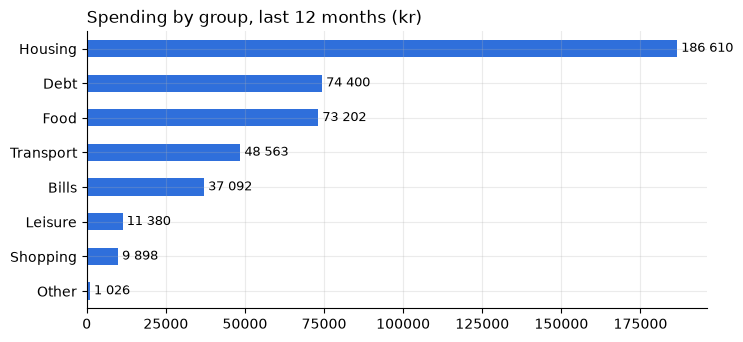

In [6]:
months = summary.index[-12:]
table = trends.monthly_by_group(df, months)
totals = table.sum().sort_values()
ax = totals.plot.barh(color=BLUE, figsize=(8, 3.6))
ax.set_title("Spending by group, last 12 months (kr)", loc="left")
for i, v in enumerate(totals):
    ax.text(v, i, f" {v:,.0f}".replace(",", " "), va="center", fontsize=9)
(totals / totals.sum() * 100).round(1).sort_values(ascending=False).rename("share %")

Fixed costs are 67% of spending


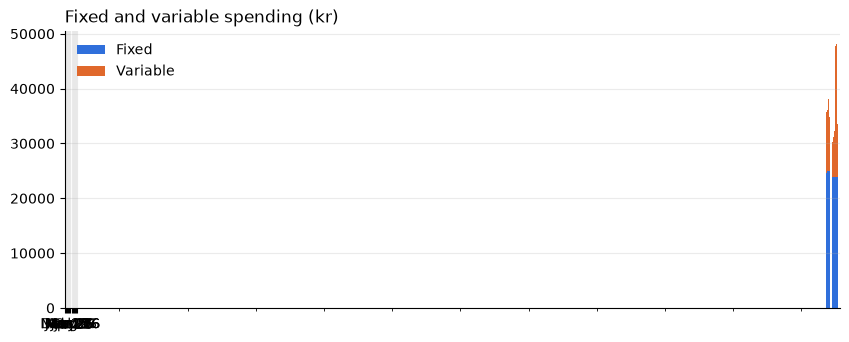

In [7]:
split = trends.fixed_and_variable(df, months)
ax = split.plot.bar(stacked=True, color=[BLUE, ORANGE], width=0.8, figsize=(10, 3.6))
ax.set_xticks(range(len(split)), [m.strftime("%b %y") for m in split.index], rotation=0)
ax.set_title("Fixed and variable spending (kr)", loc="left")
ax.legend(frameon=False)
print(f"Fixed costs are {split['Fixed'].sum() / split.to_numpy().sum():.0%} of spending")

Housing is by far the largest group. Fixed costs (rent, loans, bills) are most of
the spending, so the room for change is in the variable part: food, transport, shopping.

## 4. Recurring payments

A merchant is recurring when it was paid at least 3 times and the gaps between payments are
regular: at least 70 % of the gaps lie within ±35 % of the median gap, and the median gap
matches a cadence (weekly, monthly, quarterly, yearly). Amounts may vary (electricity).
A price change compares the last payment with the median of the earlier ones.

In [8]:
rec = recurring.find_recurring(df)
active = rec[rec["active"]]
print(f"{len(active)} active recurring payments, {active['monthly_cost'].sum():,.0f} kr a month")
active[["name", "category", "cadence", "count", "amount", "monthly_cost", "price_change"]]

11 active recurring payments, 24,526 kr a month


,name,category,cadence,count,amount,monthly_cost,price_change
0,husleie storgata,Rent & mortgage,monthly,24,14400.00,14138.71,NaN
1,santander consumer,Loans & credit,monthly,24,3250.00,3191.03,NaN
2,lånekassen efaktura,Loans & credit,monthly,24,2950.00,2896.47,NaN
3,gjensidige forsikring,Insurance,monthly,24,1120.00,1099.68,NaN
4,ruter månedsbillett,Public transport & taxi,monthly,24,899.00,882.69,NaN
5,tibber norge,Electricity,monthly,24,715.50,702.52,NaN
6,sats norge,Training,monthly,24,649.00,637.22,18.2
7,telia norge,Phone & internet,monthly,24,449.00,440.85,NaN
8,clas ohlson,Home & electronics,quarterly,5,579.29,215.03,-52.0
9,netflix.com,Subscriptions,monthly,24,179.00,175.75,NaN


In [9]:
# Why Spotify counts as monthly: the gaps between payments, in days.
spotify = df[df["merchant"] == "spotify p2c"].sort_values("date")
gaps = spotify["date"].diff().dt.days.dropna()
median = gaps.median()
regular = ((gaps - median).abs() <= 0.35 * median).mean()
print(f"Median gap {median:.0f} days; {regular:.0%} of gaps within ±35 %")
print("Amounts:", sorted(spotify["amount"].abs().unique()))

Median gap 31 days; 100% of gaps within ±35 %
Amounts: [np.float64(129.0), np.float64(149.0)]


One row is a false positive worth noticing: *clas ohlson* shows up as quarterly
because a few random shop visits happened to be about three months apart. A rule that only
looks at timing cannot tell the difference; requiring a stable amount would, at the cost of
missing bills that vary (electricity). The app keeps the looser rule and lets the user see
the payments behind each row.

Two subscriptions went up in price: the gym (+18 %) and Spotify (+16 %). Electricity
varies with the season, so its "last change" depends on the month. Price rises are easy
to miss on a bank statement
because the amounts are small and spread over the year.

## 5. Unusual months, done robustly

The naive approach is a z-score with the mean and standard deviation. But personal spending
is spiky: one large month inflates the standard deviation, and then the next spike no
longer looks unusual. The app uses a **robust z-score** instead:

$$z = \frac{x - \text{median}}{1.4826 \cdot \text{MAD}}$$

where MAD is the median absolute deviation (×1.4826 makes it comparable to a standard
deviation for normal data). A month is flagged at |z| ≥ 3, if it also differs by at least
500 kr from the typical level.

In [10]:
full = trends.monthly_by_group(df, summary.index)
flagged = anomalies.group_anomalies(full)
flagged

,month,group,amount,typical,difference,change,z
0,2026-08,Transport,15431.97,2784.96,12647.01,454.1,13.9


Transport 2026-08: 15,432 kr, typical 2,785 kr
robust z = 13.9   naive z = 13.5
with two earlier spikes: robust z = 6.3   naive z = 2.1


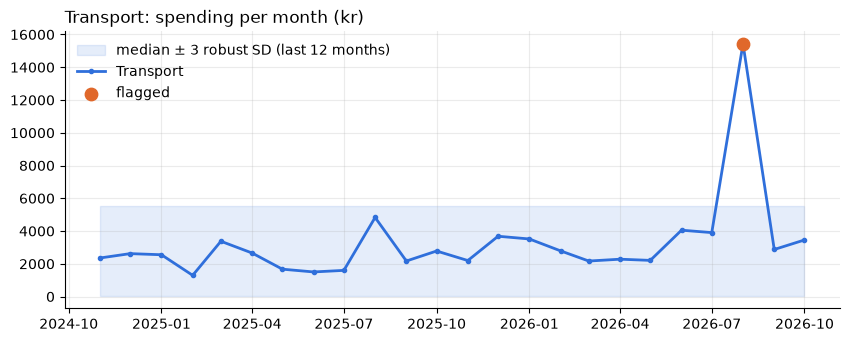

In [11]:
row = flagged.iloc[0]
group, month = row["group"], pd.Period(row["month"], freq="M")
series = full[group]
history = series[series.index < month].tail(12)
med = history.median()
mad = (history - med).abs().median() * 1.4826
naive_z = (series[month] - history.mean()) / history.std()
print(f"{group} {month}: {series[month]:,.0f} kr, typical {med:,.0f} kr")
print(f"robust z = {(series[month] - med) / mad:.1f}   naive z = {naive_z:.1f}")

# Now suppose two earlier months had been just as expensive (say, two earlier repairs).
spiky = history.copy()
spiky.iloc[[2, 7]] = series[month]
spiky_med = spiky.median()
robust = (series[month] - spiky_med) / ((spiky - spiky_med).abs().median() * 1.4826)
naive = (series[month] - spiky.mean()) / spiky.std()
print(f"with two earlier spikes: robust z = {robust:.1f}   naive z = {naive:.1f}")

x = series.index.to_timestamp()
fig, ax = plt.subplots()
ax.fill_between(
    x,
    med - 3 * mad,
    med + 3 * mad,
    color=BLUE,
    alpha=0.12,
    label="median ± 3 robust SD (last 12 months)",
)
ax.plot(x, series, color=BLUE, lw=2, marker="o", ms=3, label=group)
ax.scatter([month.to_timestamp()], [series[month]], color=ORANGE, s=80, zorder=3, label="flagged")
ax.set_title(f"{group}: spending per month (kr)", loc="left")
ax.legend(frameon=False, loc="upper left")

The car repair is flagged clearly by both methods here, because the history is calm.
The second line shows why the app uses the robust version: with two earlier spikes of the
same size, the naive z-score falls below the threshold of 3 (the spikes inflate the
standard deviation and hide the new one), while the robust z-score stays well above it.

## 6. When is the money spent?

Average variable spending per day, by weekday and month. Each cell divides by how many of
that weekday the month has, so a month with five Fridays is not unfairly high.

Most expensive weekday on average: Sun


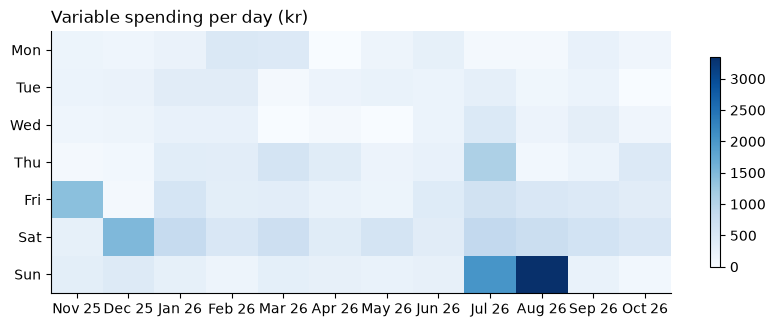

In [12]:
heat = patterns.weekday_by_month(df, months)
fig, ax = plt.subplots(figsize=(10, 3.4))
im = ax.imshow(heat.to_numpy(), cmap="Blues", aspect="auto")
ax.set_yticks(range(7), heat.index)
ax.set_xticks(range(len(months)), [m.strftime("%b %y") for m in months])
ax.grid(False)
ax.set_title("Variable spending per day (kr)", loc="left")
fig.colorbar(im, ax=ax, shrink=0.8)
print("Most expensive weekday on average:", heat.mean(axis=1).idxmax())

## 7. A realistic budget

The suggestion per group is the **median** of the last six months, rounded up to 100 kr.
Months without spending in a group count as 0, so one rare cost (the car repair) does not
inflate the budget for every month after it.

In [13]:
november = pd.Period("2026-11", freq="M")
suggested = budget.suggest(df, november)
mean = full.tail(6).mean().reindex(suggested.index).round(-2)
pd.DataFrame({"median (suggested)": suggested, "mean (for comparison)": mean})

,median (suggested),mean (for comparison)
group,,
Housing,15200.0,15100.0
Debt,6200.0,6200.0
Food,5700.0,6400.0
Transport,3700.0,5300.0
Bills,2600.0,2500.0


## 8. Paying off debt faster

Two loans: a student loan at 4.7 % and a car loan at 8.9 %. The payoff is simulated month
by month; extra money goes to the most expensive loan first (avalanche), and when a loan
is paid off, its payment moves to the next one. The simulation is checked against the
closed-form annuity formula $n = -\ln(1 - rB/P) / \ln(1 + r)$.

In [14]:
loans = [
    {"name": "Student loan", "balance": 311_200, "rate": 4.7, "payment": 2_950},
    {"name": "Car loan", "balance": 118_400, "rate": 8.9, "payment": 3_250},
]
for loan in loans:
    sim = debt.payoff(loan["balance"], loan["rate"], loan["payment"])["months"]
    exact = debt.months_closed_form(loan["balance"], loan["rate"], loan["payment"])
    print(f"{loan['name']}: simulated {sim} months, closed form {exact:.1f}")

base = debt.plan(loans)
rows = []
for extra in range(0, 5001, 500):
    p = debt.plan(loans, extra=extra)
    rows.append(
        {"extra": extra, "months": p["months"], "interest saved": base["interest"] - p["interest"]}
    )
whatif = pd.DataFrame(rows).set_index("extra")
whatif.loc[[0, 1000, 2000, 3000, 5000]]

Student loan: simulated 137 months, closed form 136.4
Car loan: simulated 43 months, closed form 42.6


,months,interest saved
extra,,
0,83,0.00
1000,70,15557.19
2000,60,26078.27
3000,53,33726.67
5000,42,44164.75


At 1 000 kr extra: 70 months instead of 83, 15,557 kr less interest


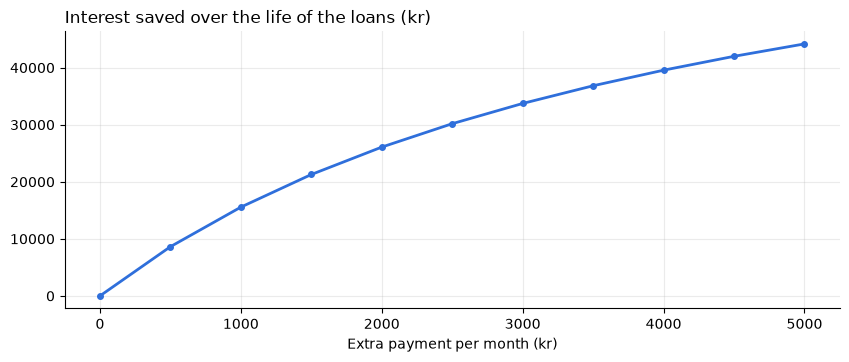

In [15]:
fig, ax = plt.subplots()
ax.plot(whatif.index, whatif["interest saved"], color=BLUE, lw=2, marker="o", ms=4)
ax.set_xlabel("Extra payment per month (kr)")
ax.set_title("Interest saved over the life of the loans (kr)", loc="left")
print(
    f"At 1 000 kr extra: {whatif.loc[1000, 'months']} months instead of "
    f"{base['months']}, {whatif.loc[1000, 'interest saved']:,.0f} kr less interest"
)

The curve flattens: each extra krone saves a little less, because the expensive car
loan is gone early and the rest goes to the cheaper student loan.

## Summary

- The household saves just under 10 % of its income. Fixed costs dominate, so the room for
  change is in the variable groups.
- Ten payments are recurring (plus one false positive); two went up in price, which a
  bank statement hides well.
- A robust z-score (median and MAD) finds the one-off car repair without being thrown off
  by earlier spikes.
- A median-based budget ignores one-off costs; a mean-based one would not.
- Paying extra on the loans saves the most per krone while the expensive loan is still
  open.

*All numbers are synthetic. The same functions run on real bank data in the app.*